In [1]:
import sys
sys.path.append("../src")
import torch
from datasets.bird_photos import BirdPhotos
from models.vae import VAEParameters
from train.train_photo_vae import train, PhotoVAETrainParameters
from IPython.display import Audio, display
from torchvision.transforms.functional import to_pil_image
import time

In [2]:
DATASET_PATH = "../data/iNaturalistPrunedResizedPhoto"
vae_parameters = VAEParameters(
    input_channels=3,
    latent_dim=4,
    reconstruction_weight=1.0,
    kl_weight=0.001,
)
train_parameters = PhotoVAETrainParameters(
    lr=0.001,
    batch_size=128,
    epochs=30,
    num_workers=16,
    model_save_path="../models/photo_vae/" + str(time.time_ns()),
    model_save_frequency=1,
    device='cuda:0',
    seed=42,
)

In [3]:
normalize_transform = lambda x: x.to(torch.float32) / 255
train_dataset = BirdPhotos(DATASET_PATH, split="train", photo_transform=normalize_transform)
val_dataset = BirdPhotos(DATASET_PATH, split="val", photo_transform=normalize_transform)

In [4]:
train_outputs = train(
    train_dataset,
    val_dataset,
    None,
    vae_parameters,
    train_parameters
)

100%|██████████| 47/47 [00:35<00:00,  1.33it/s]


Epoch 1/30 train results: total loss 0.09015013949295296, reconstruction loss 0.08830609426354251, kl loss 1.844045258022448, lr 0.0009972883382072953
Epoch 1/30 val results: total loss 0.06904042956042797, reconstruction loss 0.0669215809791646, kl loss 2.1188492166235093


 11%|█         | 149/1352 [02:02<16:28,  1.22it/s]


KeyboardInterrupt: 

In [ ]:
train_outputs.vae.eval()
outputs = train_outputs.vae(torch.unsqueeze(train_dataset[0][0].to(train_parameters.device), 0))

In [ ]:
outputs.original_input.shape

torch.Size([1, 3, 128, 128])

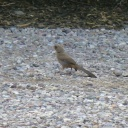

In [ ]:
display(to_pil_image((outputs.original_input.squeeze() * 255).to(torch.uint8)))

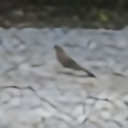

In [ ]:
display(to_pil_image((outputs.reconstructed.squeeze() * 255).to(torch.uint8)))

In [ ]:
outputs = train_outputs.vae(torch.unsqueeze(val_dataset[0][0].to(train_parameters.device), 0))

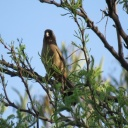

In [ ]:
display(to_pil_image((outputs.original_input.squeeze() * 255).to(torch.uint8)))

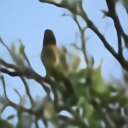

In [ ]:
display(to_pil_image((outputs.reconstructed.squeeze() * 255).to(torch.uint8)))